In [263]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import seaborn as sns
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
import joblib
import warnings

In [264]:
param_grid = [
    # 1. L1 Penalty (Lasso)
    {'solver': ['liblinear', 'saga'], 
     'penalty': ['l1'], 
     'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
     'max_iter': [1000, 2500]},
    
    # 2. L2 Penalty (Ridge)
    {'solver': ['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'], 
     'penalty': ['l2'], 
     'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
     'max_iter': [1000, 2500]},
    
    # 3. Elasticnet Penalty (Mix of L1 and L2, only supported by 'saga')
    {'solver': ['saga'], 
     'penalty': ['elasticnet'], 
     'C': [0.001, 0.01, 0.1, 1, 10, 100], 
     'l1_ratio': [0.25, 0.5, 0.75], # Controls the mix between L1 and L2
     'max_iter': [1000, 2500]},
     
    # 4. No Penalty (C parameter is ignored)
    {'solver': ['lbfgs', 'newton-cg', 'newton-cholesky', 'sag', 'saga'], 
     'penalty': [None],
     'max_iter': [1000, 2500]}
]

In [ ]:
dfTrain = pd.read_csv('train.csv')
dfTest = pd.read_csv("test.csv")
model = LogisticRegression(random_state=0, class_weight='balanced')
#model = LogisticRegression(random_state=0)
scaler = StandardScaler()

In [266]:
dfTrain.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [267]:
dfTrain = dfTrain.fillna('Unknown')

In [268]:
dfTrain['HomePlanet'].unique()

array(['Europa', 'Earth', 'Mars', 'Unknown'], dtype=object)

In [269]:
# mapping the values to numbers

dfTrain['HomePlanet'] = dfTrain['HomePlanet'].map({'Europa': 0, 'Earth': 1, 'Mars': 2, 'Unknown': 3})
dfTrain['CryoSleep'] = dfTrain['CryoSleep'].map({False: 0, True: 1, 'Unknown': 2})
dfTrain['Destination'] = dfTrain['Destination'].map({'TRAPPIST-1e': 0, 'PSO J318.5-22': 1, '55 Cancri e': 2, 'Unknown': 3})
dfTrain['VIP'] = dfTrain['VIP'].map({False: 0, True: 1, 'Unknown': 2})
dfTrain['Transported'] = dfTrain['Transported'].map({False: 0, True: 1})


In [270]:
features = ['HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
target = ['Transported']

for col in features:
    dfTrain[col] = dfTrain[col].replace('Unknown', 0).astype(float)

C:\Users\mitoc\AppData\Local\Temp\ipykernel_23036\114364907.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dfTrain[col] = dfTrain[col].replace('Unknown', 0).astype(float)
C:\Users\mitoc\AppData\Local\Temp\ipykernel_23036\114364907.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dfTrain[col] = dfTrain[col].replace('Unknown', 0).astype(float)
C:\Users\mitoc\AppData\Local\Temp\ipykernel_23036\114364907.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the 

In [271]:
x = dfTrain[features]
y = dfTrain[target]

x = scaler.fit_transform(x)

In [272]:
# Calculating the mutual information to choose the right collumns

# mutualInformation = mutual_info_classif(x, y, random_state=0)

# mutualInformationSeries = pd.Series(mutualInformation, index=x.columns)

# mutualInformationSeries = mutualInformationSeries.sort_values(ascending=False)

In [273]:
# print(mutualInformationSeries)

In [274]:
dfTrain['Total_Spent'] = dfTrain['Spa'] + dfTrain['RoomService'] + dfTrain['VRDeck'] + dfTrain['ShoppingMall'] + dfTrain['FoodCourt']

In [275]:
mutualInformationTotalSpent = mutual_info_classif(dfTrain[['Total_Spent']], y, random_state=0)
mutualInformationTotalSpentSeries = pd.Series(mutualInformationTotalSpent)
print(mutualInformationTotalSpentSeries)

0    0.131958
dtype: float64


c:\Users\mitoc\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [276]:
#features = ['CryoSleep', 'Total_Spent', 'HomePlanet']
x = dfTrain[features]
y = dfTrain[target]

In [277]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

In [278]:
grid_search = GridSearchCV(model, param_grid, cv=5, scoring='accuracy', n_jobs=-1)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    grid_search.fit(x, y.values.ravel())

model = grid_search.best_estimator_
#model.fit(x, y.values.ravel())

In [279]:
predictions = model.predict(x_test)

In [280]:
cm = confusion_matrix(y_test, predictions)

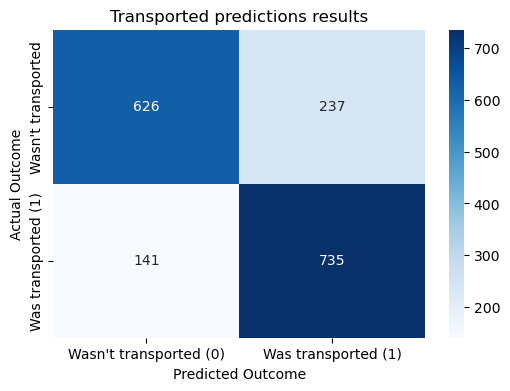

In [281]:
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=["Wasn't transported (0)", 'Was transported (1)'], 
            yticklabels=["Wasn't transported", 'Was transported (1)'])

plt.xlabel('Predicted Outcome')
plt.ylabel('Actual Outcome')
plt.title('Transported predictions results')
plt.show()

In [282]:
# mapping the values to numbers

dfTest['HomePlanet'] = dfTest['HomePlanet'].map({'Europa': 0, 'Earth': 1, 'Mars': 2, 'Unknown': 3})
dfTest['CryoSleep'] = dfTest['CryoSleep'].map({False: 0, True: 1, 'Unknown': 2})
dfTest['Destination'] = dfTest['Destination'].map({'TRAPPIST-1e': 0, 'PSO J318.5-22': 1, '55 Cancri e': 2, 'Unknown': 3})
dfTest['VIP'] = dfTest['VIP'].map({False: 0, True: 1, 'Unknown': 2})

In [283]:
xTest = dfTest[features]
xTest = scaler.transform(xTest)

In [284]:
print(features)

['HomePlanet', 'CryoSleep', 'Destination', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']


In [285]:
# print(xTest.isna().sum())

In [286]:
dfTest = dfTest.fillna('Unknown')

for col in features:
    dfTest[col] = dfTest[col].replace('Unknown', 0).astype(float)

C:\Users\mitoc\AppData\Local\Temp\ipykernel_23036\3970219169.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dfTest[col] = dfTest[col].replace('Unknown', 0).astype(float)
C:\Users\mitoc\AppData\Local\Temp\ipykernel_23036\3970219169.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dfTest[col] = dfTest[col].replace('Unknown', 0).astype(float)
C:\Users\mitoc\AppData\Local\Temp\ipykernel_23036\3970219169.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the o

In [287]:
xTest = dfTest[features]

In [288]:
predictionsTest = model.predict(xTest)

In [289]:
print(predictionsTest)

[1 0 1 ... 1 1 1]


In [290]:
submission = pd.DataFrame({
    'PassengerId': dfTest['PassengerId'],
    'Transported': predictionsTest
})

In [291]:
submission['Transported'] = submission['Transported'].astype(bool)

In [292]:
submission.to_csv('submission.csv', index=False)